# 10. Deep Learning secuencial para clasificación de URLs

Este notebook continúa el pipeline de LinkShield AI utilizando la URL original de
`dataset-phishing-clean.csv`. Entrena y compara tres arquitecturas independientes:

- **CNN 1D**, especializada en patrones locales de caracteres.
- **BiLSTM**, orientada a relaciones bidireccionales dentro de la secuencia.
- **GRU**, alternativa recurrente compacta.

La partición separa entrenamiento, validación, calibración y prueba. El conjunto de
calibración queda reservado para el modelo híbrido del notebook 11 y el conjunto de
prueba permanece intacto para la evaluación final.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

import hashlib
import json
import random
import shutil
from datetime import datetime, timezone
from pathlib import Path
from urllib.parse import quote

import matplotlib.pyplot as plt
import nbformat
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import tensorflow as tf
from IPython.display import Image, display
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, f1_score,
    precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import train_test_split
from tensorflow import keras
from tensorflow.keras import layers

DATASET_PATH = Path("dataset-phishing-clean.csv")
OUTPUT_DIR = Path("models/sequential")
PLOT_DIR = OUTPUT_DIR / "plots"
RANDOM_STATE = 42
MAX_LENGTH = 200
EMBEDDING_DIM = 24
BATCH_SIZE = 128
MAX_EPOCHS = 16

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)

TensorFlow: 2.21.0
Keras: 3.14.0


## 1. Reproducibilidad

In [2]:
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
tf.keras.utils.set_random_seed(RANDOM_STATE)
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

## 2. Dataset y secuencias

In [3]:
dataframe = pd.read_csv(DATASET_PATH)
assert {"url", "status"}.issubset(dataframe.columns)
dataframe = dataframe.dropna(subset=["url", "status"]).reset_index(drop=True)
def normalize_url_sequence(value):
    return quote(str(value).strip(), safe=":/?#[]@!$&'()*+,;=%-._~")

dataframe["url"] = dataframe["url"].map(normalize_url_sequence)
dataframe["status"] = dataframe["status"].astype("int32")
assert set(dataframe["status"].unique()) == {0, 1}
assert dataframe["url"].map(lambda value: all(ord(char) < 128 for char in value)).all()

lengths = dataframe["url"].str.len()
display(dataframe[["url", "status"]].head())
display(lengths.describe(percentiles=[0.90, 0.95, 0.975, 0.99]).to_frame("longitud"))
print("Muestras:", len(dataframe), "Balance:", dataframe["status"].value_counts().to_dict())

Muestras: 11429 Balance: {0: 5715, 1: 5714}


,url,status
0,http://www.crestonwood.com/router.php,0
1,http://shadetreetechnology.com/V4/validation/a...,1
2,https://support-appleld.com.secureupdate.duila...,1
3,http://rgipt.ac.in,0
4,http://www.iracing.com/tracks/gateway-motorspo...,0


,longitud
count,11429.000000
mean,61.187680
std,55.815663
min,12.000000
90%,111.000000
95%,132.000000
97.5%,177.300000
99%,263.000000
max,1641.000000


## 3. Partición común sin fuga de datos

In [4]:
all_indices = np.arange(len(dataframe))
y_all = dataframe["status"].to_numpy()
development_indices, test_indices = train_test_split(
    all_indices, test_size=0.20, random_state=RANDOM_STATE, stratify=y_all,
)
train_validation_indices, calibration_indices = train_test_split(
    development_indices,
    test_size=0.125,
    random_state=RANDOM_STATE,
    stratify=y_all[development_indices],
)
train_indices, validation_indices = train_test_split(
    train_validation_indices,
    test_size=1 / 7,
    random_state=RANDOM_STATE,
    stratify=y_all[train_validation_indices],
)

split_indices = {
    "train": np.sort(train_indices),
    "validation": np.sort(validation_indices),
    "calibration": np.sort(calibration_indices),
    "test": np.sort(test_indices),
}
np.savez(OUTPUT_DIR / "split_indices.npz", **split_indices)

def split_values(name):
    indices = split_indices[name]
    return dataframe.loc[indices, "url"].to_numpy(dtype=str), y_all[indices]

X_train, y_train = split_values("train")
X_validation, y_validation = split_values("validation")
X_calibration, y_calibration = split_values("calibration")
X_test, y_test = split_values("test")

split_table = pd.DataFrame([
    {"partición": name, "muestras": len(indices),
     "legítimas": int((y_all[indices] == 0).sum()),
     "phishing": int((y_all[indices] == 1).sum())}
    for name, indices in split_indices.items()
])
display(split_table)
assert sum(len(value) for value in split_indices.values()) == len(dataframe)

,partición,muestras,legítimas,phishing
0,train,6857,3428,3429
1,validation,1143,572,571
2,calibration,1143,572,571
3,test,2286,1143,1143


## 4. Vectorización por caracteres

In [5]:
vectorizer = layers.TextVectorization(
    standardize=None,
    split="character",
    output_mode="int",
    output_sequence_length=MAX_LENGTH,
    name="character_vectorizer",
)
vectorizer.adapt(tf.data.Dataset.from_tensor_slices(X_train).batch(256))
vocabulary = vectorizer.get_vocabulary()
(OUTPUT_DIR / "character_vocabulary.json").write_text(
    json.dumps(vocabulary, ensure_ascii=False, indent=2), encoding="utf-8"
)
print("Vocabulario:", len(vocabulary), "Longitud máxima:", MAX_LENGTH)

def cloned_vectorizer():
    layer = layers.TextVectorization.from_config(vectorizer.get_config())
    layer.set_vocabulary(vocabulary)
    return layer

def dataset_for(urls, labels=None, shuffle=False):
    if labels is None:
        dataset = tf.data.Dataset.from_tensor_slices(urls)
    else:
        dataset = tf.data.Dataset.from_tensor_slices((urls, labels))
    if shuffle:
        dataset = dataset.shuffle(len(urls), seed=RANDOM_STATE, reshuffle_each_iteration=True)
    return dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_dataset = dataset_for(X_train, y_train, shuffle=True)
validation_dataset = dataset_for(X_validation, y_validation)
test_dataset = dataset_for(X_test, y_test)

Vocabulario: 87 Longitud máxima: 200


## 5. Arquitecturas

In [6]:
def compile_model(model):
    model.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss="binary_crossentropy",
        metrics=[
            keras.metrics.BinaryAccuracy(name="accuracy"),
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall"),
            keras.metrics.AUC(name="roc_auc"),
        ],
    )
    return model

def base_input():
    inputs = keras.Input(shape=(), dtype=tf.string, name="url")
    tokens = cloned_vectorizer()(inputs)
    embedded = layers.Embedding(len(vocabulary), EMBEDDING_DIM, mask_zero=False)(tokens)
    return inputs, embedded

def build_cnn():
    inputs, x = base_input()
    x = layers.SeparableConv1D(64, 5, padding="same", activation="relu")(x)
    x = layers.MaxPooling1D(2)(x)
    x = layers.SeparableConv1D(96, 3, padding="same", activation="relu")(x)
    x = layers.GlobalMaxPooling1D()(x)
    x = layers.Dense(48, activation="relu")(x)
    x = layers.Dropout(0.25)(x)
    return compile_model(keras.Model(inputs, layers.Dense(1, activation="sigmoid")(x), name="cnn_1d_url"))

def build_bilstm():
    inputs, x = base_input()
    x = layers.Bidirectional(layers.LSTM(24))(x)
    x = layers.Dense(32, activation="relu")(x)
    x = layers.Dropout(0.25)(x)
    return compile_model(keras.Model(inputs, layers.Dense(1, activation="sigmoid")(x), name="bilstm_url"))

def build_gru():
    inputs, x = base_input()
    x = layers.GRU(40)(x)
    x = layers.Dense(32, activation="relu")(x)
    x = layers.Dropout(0.20)(x)
    return compile_model(keras.Model(inputs, layers.Dense(1, activation="sigmoid")(x), name="gru_url"))

builders = {
    "cnn_1d": ("CNN 1D por caracteres", build_cnn),
    "bilstm": ("BiLSTM por caracteres", build_bilstm),
    "gru": ("GRU por caracteres", build_gru),
}
for model_id, (display_name, builder) in builders.items():
    preview = builder()
    print(model_id, display_name, preview.count_params(), "parámetros")
    del preview
keras.backend.clear_session()

cnn_1d CNN 1D por caracteres 14945 parámetros
bilstm BiLSTM por caracteres 13097 parámetros
gru GRU por caracteres 11353 parámetros


## 6. Entrenamiento

In [7]:
models = {}
histories = {}
training_rows = []
for index, (model_id, (display_name, builder)) in enumerate(builders.items()):
    tf.keras.utils.set_random_seed(RANDOM_STATE + index)
    model = builder()
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, min_delta=1e-4, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5, verbose=1),
    ]
    print("\n" + "=" * 72, "\nENTRENANDO:", display_name, "\n" + "=" * 72)
    history = model.fit(
        train_dataset,
        validation_data=validation_dataset,
        epochs=MAX_EPOCHS,
        callbacks=callbacks,
        verbose=2,
    )
    models[model_id] = model
    histories[model_id] = history.history
    training_rows.append({
        "model_id": model_id,
        "epochs_completed": len(history.history["loss"]),
        "best_epoch": int(np.argmin(history.history["val_loss"]) + 1),
        "best_val_loss": float(np.min(history.history["val_loss"])),
    })
display(pd.DataFrame(training_rows))


ENTRENANDO: CNN 1D por caracteres 
Epoch 1/16
54/54 - 2s - 45ms/step - accuracy: 0.5009 - loss: 0.6911 - precision: 0.5005 - recall: 1.0000 - roc_auc: 0.5613 - val_accuracy: 0.4996 - val_loss: 0.6799 - val_precision: 0.4996 - val_recall: 1.0000 - val_roc_auc: 0.7815 - learning_rate: 0.0010
Epoch 2/16
54/54 - 1s - 19ms/step - accuracy: 0.6736 - loss: 0.6281 - precision: 0.6321 - recall: 0.8311 - roc_auc: 0.7614 - val_accuracy: 0.7305 - val_loss: 0.5671 - val_precision: 0.7573 - val_recall: 0.6778 - val_roc_auc: 0.8340 - learning_rate: 0.0010
Epoch 3/16
54/54 - 1s - 19ms/step - accuracy: 0.7777 - loss: 0.4831 - precision: 0.7923 - recall: 0.7530 - roc_auc: 0.8504 - val_accuracy: 0.8014 - val_loss: 0.4328 - val_precision: 0.8346 - val_recall: 0.7513 - val_roc_auc: 0.8867 - learning_rate: 0.0010
Epoch 4/16
54/54 - 1s - 18ms/step - accuracy: 0.8095 - loss: 0.4190 - precision: 0.8273 - recall: 0.7824 - roc_auc: 0.8876 - val_accuracy: 0.8163 - val_loss: 0.4119 - val_precision: 0.8139 - val_r

,model_id,epochs_completed,best_epoch,best_val_loss
0,cnn_1d,16,16,0.341116
1,bilstm,10,7,0.379540
2,gru,16,16,0.364897


## 7. Curvas de aprendizaje

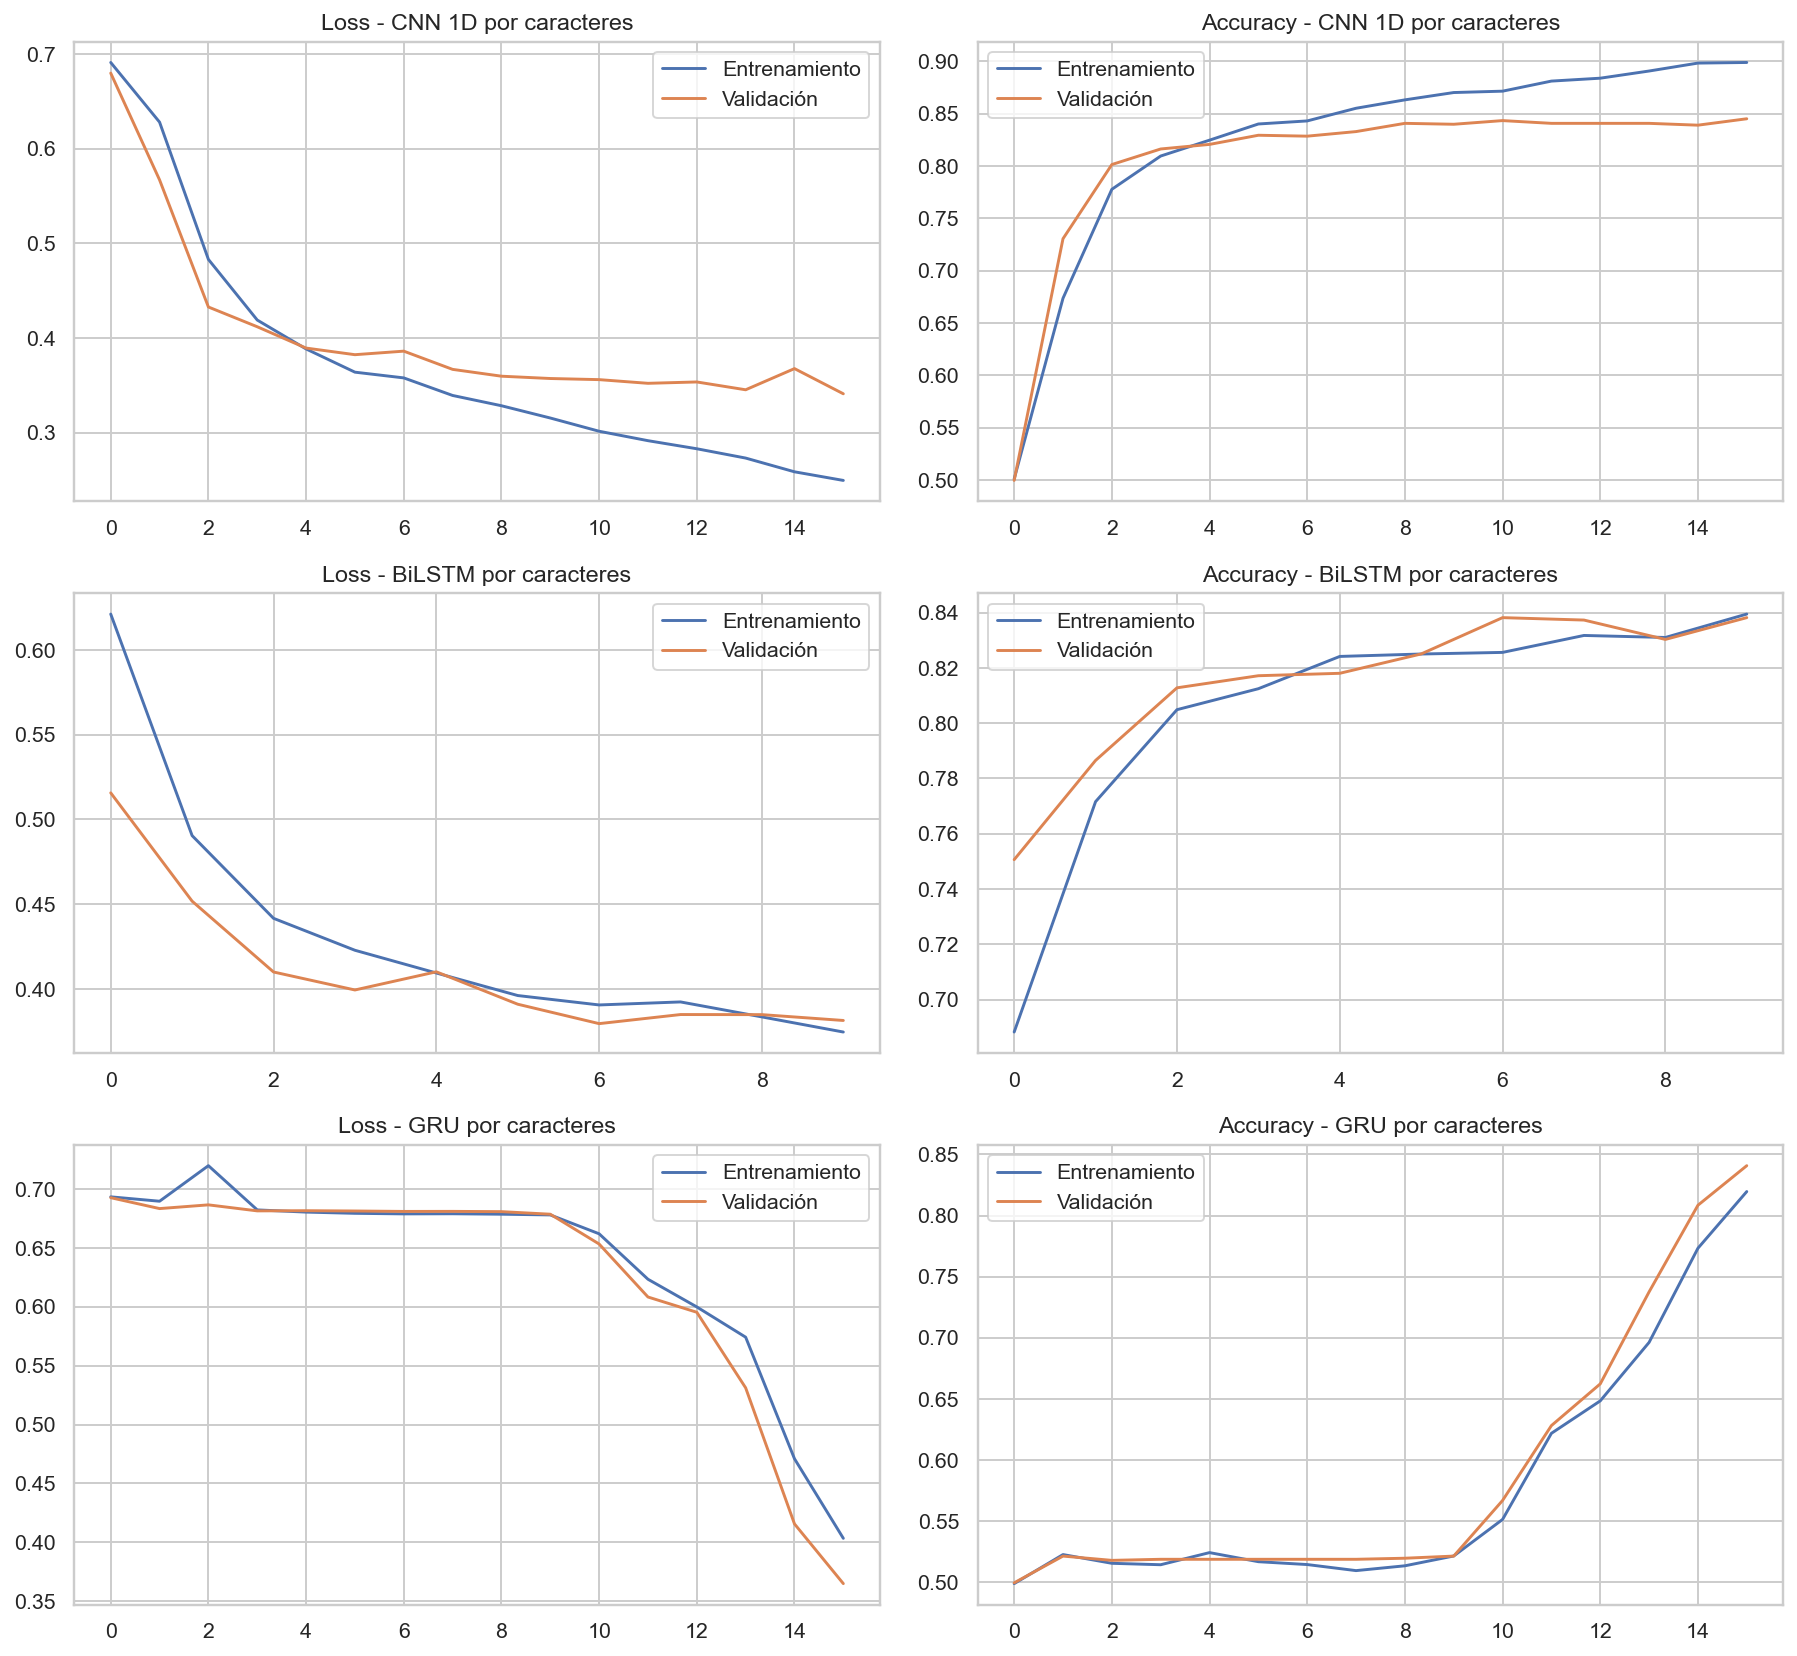

In [8]:
fig, axes = plt.subplots(len(histories), 2, figsize=(13, 4 * len(histories)))
for row, (model_id, history) in enumerate(histories.items()):
    axes[row, 0].plot(history["loss"], label="Entrenamiento")
    axes[row, 0].plot(history["val_loss"], label="Validación")
    axes[row, 0].set_title(f"Loss - {builders[model_id][0]}")
    axes[row, 0].legend()
    axes[row, 1].plot(history["accuracy"], label="Entrenamiento")
    axes[row, 1].plot(history["val_accuracy"], label="Validación")
    axes[row, 1].set_title(f"Accuracy - {builders[model_id][0]}")
    axes[row, 1].legend()
plt.tight_layout()
curves_path = PLOT_DIR / "curvas_secuenciales.png"
plt.savefig(curves_path, dpi=140, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(curves_path)))

## 8. Umbrales y evaluación final

In [9]:
def best_threshold(labels, probabilities):
    candidates = np.linspace(0.20, 0.80, 121)
    scores = [f1_score(labels, probabilities >= threshold) for threshold in candidates]
    return float(candidates[int(np.argmax(scores))])

evaluation_rows = []
confusion_matrices = {}
thresholds = {}
for model_id, model in models.items():
    validation_probabilities = model.predict(dataset_for(X_validation), verbose=0).reshape(-1)
    threshold = best_threshold(y_validation, validation_probabilities)
    thresholds[model_id] = threshold
    probabilities = model.predict(dataset_for(X_test), verbose=0).reshape(-1)
    predictions = (probabilities >= threshold).astype("int32")
    tn, fp, fn, tp = confusion_matrix(y_test, predictions, labels=[0, 1]).ravel()
    confusion_matrices[model_id] = np.array([[tn, fp], [fn, tp]])
    evaluation_rows.append({
        "model_id": model_id, "modelo": builders[model_id][0], "threshold": threshold,
        "accuracy": accuracy_score(y_test, predictions),
        "precision": precision_score(y_test, predictions),
        "recall": recall_score(y_test, predictions),
        "f1": f1_score(y_test, predictions),
        "roc_auc": roc_auc_score(y_test, probabilities),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    })
    print("\n", builders[model_id][0])
    print(classification_report(y_test, predictions, target_names=["Legítima", "Phishing"]))

results_df = pd.DataFrame(evaluation_rows).sort_values("f1", ascending=False).reset_index(drop=True)
metric_columns = ["threshold", "accuracy", "precision", "recall", "f1", "roc_auc"]
display(results_df.assign(**{column: results_df[column].round(4) for column in metric_columns}))


 CNN 1D por caracteres
              precision    recall  f1-score   support

    Legítima       0.90      0.81      0.85      1143
    Phishing       0.83      0.91      0.87      1143

    accuracy                           0.86      2286
   macro avg       0.86      0.86      0.86      2286
weighted avg       0.86      0.86      0.86      2286


 BiLSTM por caracteres
              precision    recall  f1-score   support

    Legítima       0.88      0.75      0.81      1143
    Phishing       0.78      0.89      0.83      1143

    accuracy                           0.82      2286
   macro avg       0.83      0.82      0.82      2286
weighted avg       0.83      0.82      0.82      2286


 GRU por caracteres
              precision    recall  f1-score   support

    Legítima       0.88      0.78      0.83      1143
    Phishing       0.80      0.89      0.84      1143

    accuracy                           0.84      2286
   macro avg       0.84      0.84      0.84      2286
weigh

,model_id,modelo,threshold,accuracy,precision,recall,f1,roc_auc,tn,fp,fn,tp
0,cnn_1d,CNN 1D por caracteres,0.250,0.8605,0.8275,0.9108,0.8671,0.9441,926,217,102,1041
1,gru,GRU por caracteres,0.405,0.8355,0.8027,0.8898,0.8440,0.9170,893,250,126,1017
2,bilstm,BiLSTM por caracteres,0.380,0.8211,0.7802,0.8941,0.8333,0.9090,855,288,121,1022


## 9. Matrices de confusión

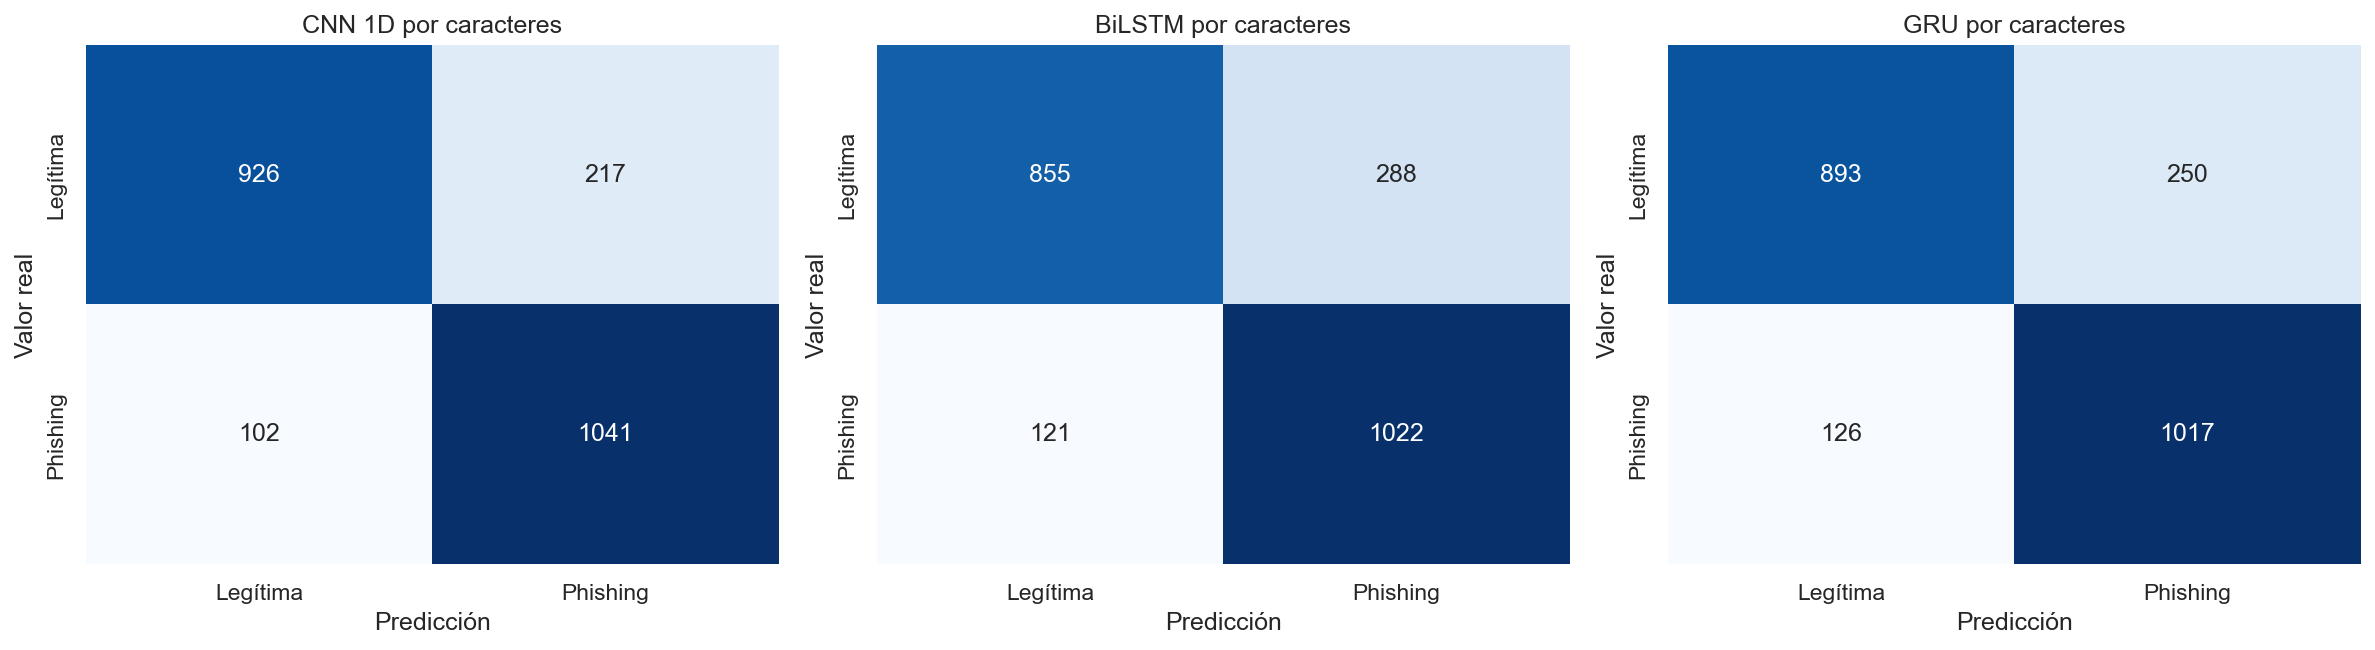

In [10]:
fig, axes = plt.subplots(1, len(confusion_matrices), figsize=(16, 4.5))
for axis, (model_id, matrix) in zip(axes, confusion_matrices.items()):
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["Legítima", "Phishing"], yticklabels=["Legítima", "Phishing"], ax=axis)
    axis.set_title(builders[model_id][0])
    axis.set_xlabel("Predicción")
    axis.set_ylabel("Valor real")
plt.tight_layout()
matrix_path = PLOT_DIR / "matrices_secuenciales.png"
plt.savefig(matrix_path, dpi=150, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(matrix_path)))

## 10. Exportación y verificación

In [11]:
def artifact_id(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()[:12]

best_model_id = str(results_df.iloc[0]["model_id"])
exported_at = datetime.now(timezone.utc).isoformat()
artifacts = []
for row in results_df.to_dict("records"):
    model_id = row["model_id"]
    artifact_path = OUTPUT_DIR / f"{model_id}.keras"
    models[model_id].save(artifact_path)
    training = next(item for item in training_rows if item["model_id"] == model_id)
    artifact = {
        "id": model_id,
        "display_name": builders[model_id][0],
        "family": "deep_learning_sequential",
        "runtime_type": "keras_sequence",
        "artifact": artifact_path.name,
        "artifact_id": artifact_id(artifact_path),
        "recommended_in_family": model_id == best_model_id,
        "threshold": float(row["threshold"]),
        "parameter_count": int(models[model_id].count_params()),
        "metrics": {key: float(row[key]) for key in ("accuracy", "precision", "recall", "f1", "roc_auc")},
        "confusion_matrix": {key: int(row[key]) for key in ("tn", "fp", "fn", "tp")},
        "training": training,
    }
    artifacts.append(artifact)
    (OUTPUT_DIR / f"history_{model_id}.json").write_text(
        json.dumps({key: [float(value) for value in values] for key, values in histories[model_id].items()}, indent=2),
        encoding="utf-8",
    )

shutil.copy2(OUTPUT_DIR / f"{best_model_id}.keras", OUTPUT_DIR / "mejor_modelo_secuencial.keras")
results_df.to_csv(OUTPUT_DIR / "metricas_modelos_secuenciales.csv", index=False)
registry = {
    "schema_version": 1,
    "exported_at": exported_at,
    "framework": "TensorFlow/Keras",
    "tensorflow_version": tf.__version__,
    "dataset": {"name": DATASET_PATH.name, "total_rows": len(dataframe),
                **{f"{name}_rows": len(indices) for name, indices in split_indices.items()}},
    "sequence": {"encoding": "character", "max_length": MAX_LENGTH, "vocabulary_size": len(vocabulary)},
    "best_model_id": best_model_id,
    "models": artifacts,
}
(OUTPUT_DIR / "sequential_registry.json").write_text(json.dumps(registry, ensure_ascii=False, indent=2), encoding="utf-8")

for artifact in artifacts:
    loaded = keras.models.load_model(OUTPUT_DIR / artifact["artifact"])
    sample = loaded.predict(dataset_for(X_test[:2]), verbose=0).reshape(-1)
    assert sample.shape == (2,) and np.isfinite(sample).all()
    print(artifact["id"], "recargado:", np.round(sample, 5).tolist())
print("Mejor modelo secuencial:", best_model_id)

cnn_1d recargado: [0.9948199987411499, 0.04416000097990036]
gru recargado: [0.9522600173950195, 0.034460000693798065]
bilstm recargado: [0.9790599942207336, 0.07385999709367752]
Mejor modelo secuencial: cnn_1d


## Conclusión

Los tres modelos quedan disponibles como clasificadores independientes. El registro y
los índices exportados permiten que el notebook 11 entrene el ensamble híbrido sobre
calibración y lo evalúe posteriormente sobre un test que ningún metaclasificador ha visto.